In [1]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from google.colab import files

uploaded = files.upload()
filename = next(iter(uploaded))

df = pd.read_csv(filename)

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nFirst five rows:")
display(df.head())

print("\nData types:")
print(df.dtypes)


Saving raw_retail_sales_12000.csv to raw_retail_sales_12000.csv
Dataset shape: (12100, 9)

Column names:
['transaction_id', 'datetime', 'store_id', 'product', 'department', 'quantity', 'unit_price', 'line_total', 'payment']

First five rows:


,transaction_id,datetime,store_id,product,department,quantity,unit_price,line_total,payment
0,600001,2025-01-01 00:00:00,S3,Bread,Bakery,5.0,2.49,12.45,UPI
1,600002,2025-01-01 01:16:26,S3,Tortilla Chips,Snacks,1.0,3.49,3.49,UPI
2,600003,2025-01-01 02:32:53,S3,Apples,Produce,5.0,1.99,9.95,UPI
3,600004,2025-01-01 03:49:20,S2,Salsa,Snacks,7.0,3.99,27.93,Card
4,600005,2025-01-01 05:05:47,S2,Bread,Bakery,unknown,2.49,4.98,Card



Data types:
transaction_id      int64
datetime           object
store_id           object
product            object
department         object
quantity           object
unit_price        float64
line_total        float64
payment            object
dtype: object


In [2]:

numeric_df = df.select_dtypes(include="number")

print("Descriptive Statistics")
display(numeric_df.describe().T)

print("\nMedian values:")
display(numeric_df.median().to_frame("Median"))

print("\nMissing values:")
display(df.isnull().sum().to_frame("Missing Values"))

print("\nDuplicate rows:", df.duplicated().sum())


Descriptive Statistics


,count,mean,std,min,25%,50%,75%,max
transaction_id,12100.0,606002.462397,3465.713599,600001.00,602999.75,606001.50,609006.25,612000.00
unit_price,11950.0,4.259540,2.159542,1.29,2.49,3.99,5.99,8.49
line_total,11949.0,17.072517,12.994966,1.29,6.98,13.93,23.96,59.43



Median values:


,Median
transaction_id,606001.50
unit_price,3.99
line_total,13.93



Missing values:


,Missing Values
transaction_id,0
datetime,153
store_id,151
product,151
department,150
quantity,150
unit_price,150
line_total,151
payment,150



Duplicate rows: 100


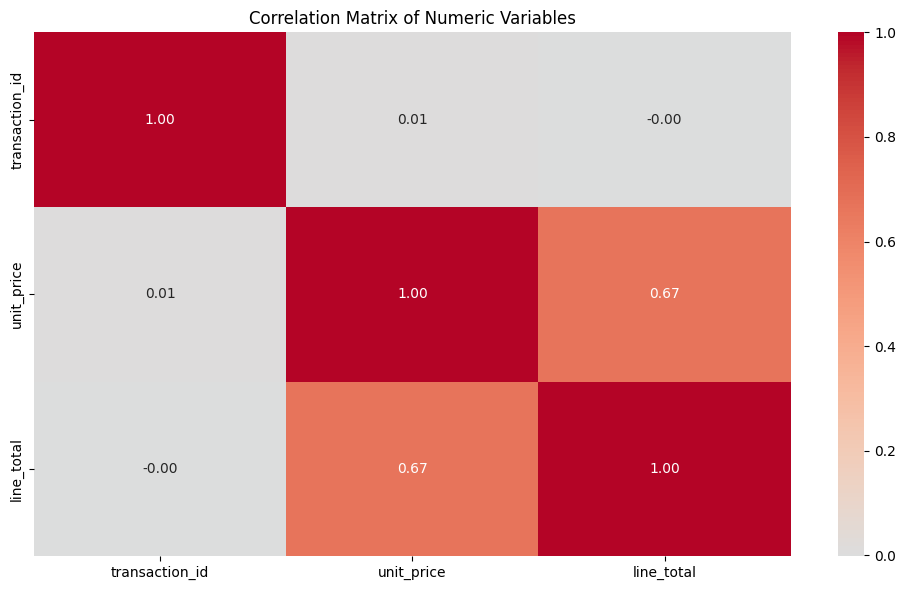

In [3]:

plt.figure(figsize=(10, 6))
sns.heatmap(
    numeric_df.corr(),
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    center=0
)
plt.title("Correlation Matrix of Numeric Variables")
plt.tight_layout()
plt.show()


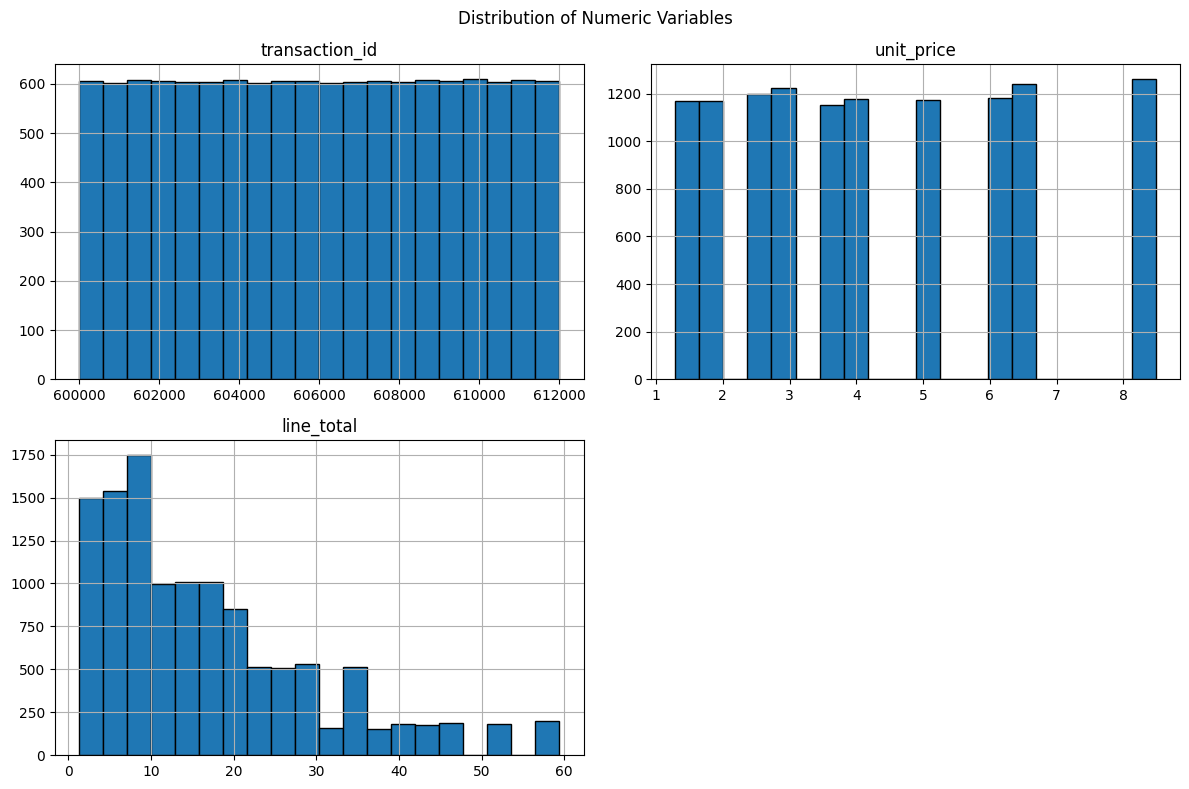

In [4]:

numeric_df.hist(figsize=(12, 8), bins=20, edgecolor="black")
plt.suptitle("Distribution of Numeric Variables")
plt.tight_layout()
plt.show()


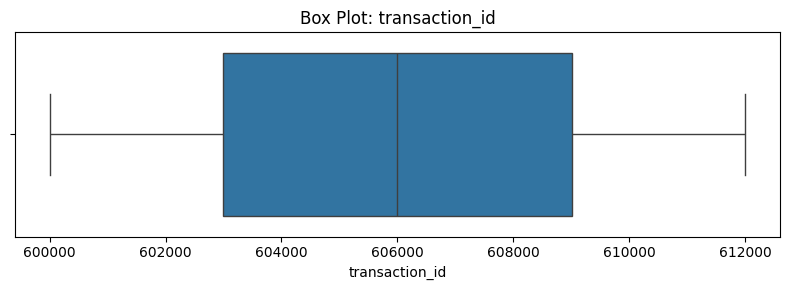

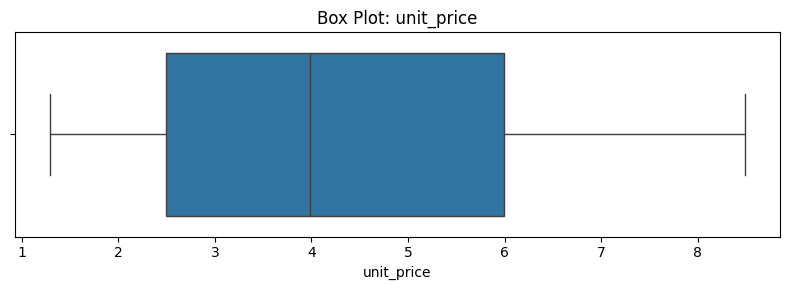

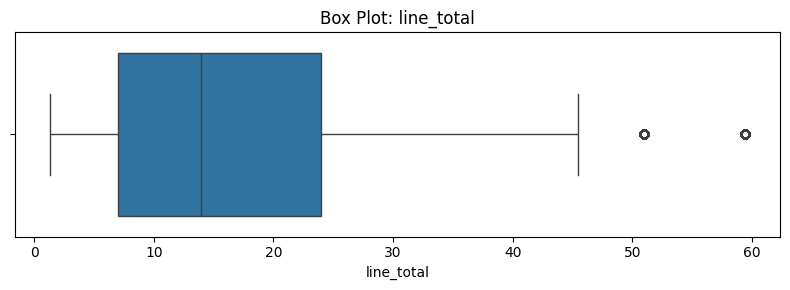

In [5]:

for col in numeric_df.columns:
    plt.figure(figsize=(8, 3))
    sns.boxplot(x=numeric_df[col])
    plt.title(f"Box Plot: {col}")
    plt.tight_layout()
    plt.show()


In [6]:

print(df.columns.tolist())


['transaction_id', 'datetime', 'store_id', 'product', 'department', 'quantity', 'unit_price', 'line_total', 'payment']


In [7]:

# Hypothesis 1: Unit price and quantity sold
from scipy import stats
import pandas as pd
import numpy as np

required = ["unit_price", "quantity", "line_total", "datetime"]
missing = [c for c in required if c not in df.columns]

if missing:
    print("These columns are missing:", missing)
    print("Available columns:", df.columns.tolist())
else:
    # Prepare the relevant data
    h1 = df[["unit_price", "quantity"]].dropna()
    r1, p1 = stats.spearmanr(
        h1["unit_price"], h1["quantity"]
    )

    print("H1: Unit price is associated with quantity sold")
    print("Spearman correlation:", round(r1, 3))
    print("P-value:", round(p1, 4))

    if p1 < 0.05:
        print("Result: Statistically significant association.")
    else:
        print("Result: No statistically significant association.")

    # Hypothesis 2: Quantity and total sales
    h2 = df[["quantity", "line_total"]].dropna()
    r2, p2 = stats.spearmanr(
        h2["quantity"], h2["line_total"]
    )

    print("\nH2: Quantity is associated with total sales")
    print("Spearman correlation:", round(r2, 3))
    print("P-value:", round(p2, 4))

    if p2 < 0.05:
        print("Result: Statistically significant association.")
    else:
        print("Result: No statistically significant association.")

    # Hypothesis 3: Average sales differ by month
    monthly_df = df[["datetime", "line_total"]].dropna().copy()
    monthly_df["month"] = pd.to_datetime(
        monthly_df["datetime"], errors="coerce"
    ).dt.month
    monthly_df = monthly_df.dropna(subset=["month"])

    groups = [
        group["line_total"].values
        for _, group in monthly_df.groupby("month")
        if len(group) >= 2
    ]

    if len(groups) >= 2:
        f_stat, p3 = stats.f_oneway(*groups)
        print("\nH3: Average sales differ across calendar months")
        print("ANOVA F-statistic:", round(f_stat, 3))
        print("P-value:", round(p3, 4))

        if p3 < 0.05:
            print("Result: At least one month's mean differs significantly.")
        else:
            print("Result: No statistically significant difference detected.")
    else:
        print("\nNot enough monthly groups to test H3.")


H1: Unit price is associated with quantity sold
Spearman correlation: 0.003
P-value: 0.7638
Result: No statistically significant association.

H2: Quantity is associated with total sales
Spearman correlation: 0.709
P-value: 0.0
Result: Statistically significant association.

H3: Average sales differ across calendar months
ANOVA F-statistic: 0.814
P-value: 0.6266
Result: No statistically significant difference detected.


## Top 5 Critical Findings

1. **Dataset overview:** The dataset contains ___ rows and ___ columns.
2. **Sales statistics:** The average sales value is ___, and the median is ___.
3. **Distribution:** The histogram shows that ___.
4. **Correlation:** The relationship between ___ and ___ is ___.
5. **Hypothesis testing:** Out of three hypotheses, ___ showed statistically significant evidence at the 5% significance level.

## Conclusion

The analysis used descriptive statistics, visualizations, and hypothesis testing to explore retail sales patterns. The results help identify relationships between business variables and areas that may need further investigation.